<a href="https://colab.research.google.com/github/tonia-3/Customer-Segmentation-Analysis/blob/main/customer_segmentation_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

##Customer Segmentation Using Clustering


We introduce the dataset (Mall Customers) and discuss its columns like Age, Annual Income, Spending Score, and Gender. The primary goal is to perform customer segmentation using these variables.

Customer segmentation is a crucial aspect of marketing and business strategy that involves dividing a customer base into distinct groups based on various characteristics. This project aims to utilize clustering techniques to identify and analyze these segments, allowing businesses to tailor their marketing efforts and improve customer satisfaction. By leveraging customer data, we can uncover hidden patterns and preferences, facilitating more effective communication and product offerings.

The primary objective of this project is to develop a robust customer segmentation model using clustering algorithms such as K-means or hierarchical clustering. The model will group customers based on factors such as demographics, purchasing behavior, and preferences. This segmentation will enable businesses to:



*   Identify high-value customer segments for targeted marketing campaigns.
*   Enhance customer engagement by personalizing services and products.
*   Improve customer retention by understanding and addressing the specific needs of each segment.
*   Optimize resource allocation by focusing efforts on the most profitable segments.




In [33]:
#convert interactive charts into static PNG images
!pip install -q kaleido==0.2.1 "plotly<6.0.0"


In [2]:
#import the libraries
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
import warnings
warnings.filterwarnings('ignore')


In [3]:
df=pd.read_csv('Mall_Customers.csv')

In [4]:
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


<Axes: xlabel='Annual Income (k$)', ylabel='Count'>

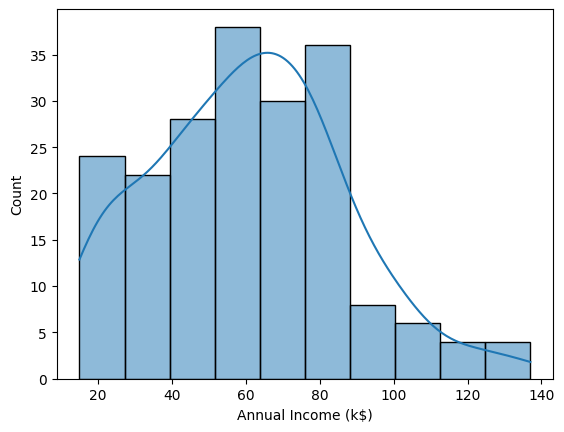

In [35]:
sns.histplot(df['Annual Income (k$)'], kde=True)

In [6]:
df.columns

Index(['CustomerID', 'Gender', 'Age', 'Annual Income (k$)',
       'Spending Score (1-100)'],
      dtype='object')

The distribution plot helps to visualize the spread and shape of the data revealing insights like skewness or outliers.

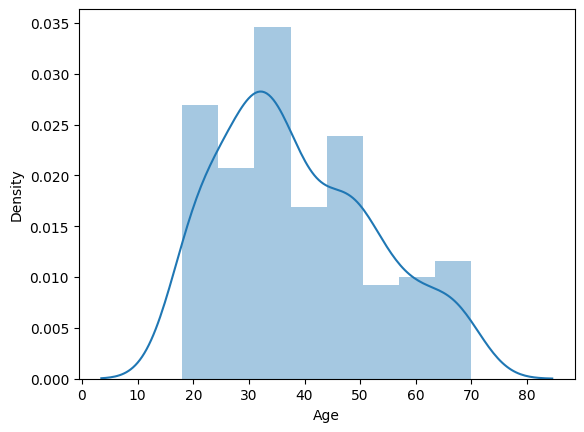

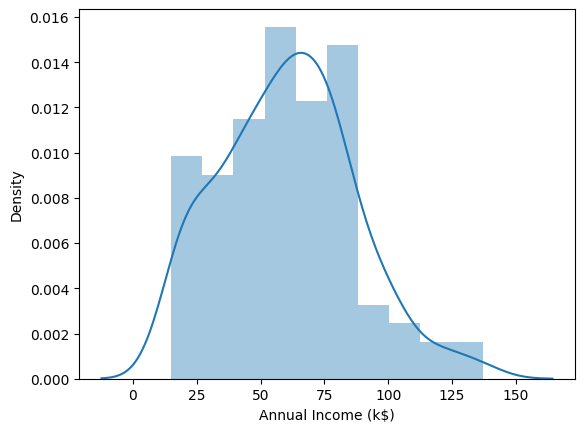

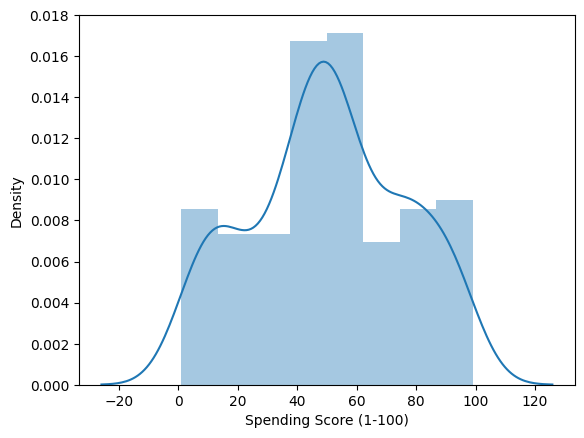

In [7]:
columns = ['Age', 'Annual Income (k$)',
       'Spending Score (1-100)']
for i in columns:
    plt.figure()
    sns.distplot(df[i])

Boxplots by gender allow comparison of income and spending behavior across genders, helping identify trends and differences between male and female customers.

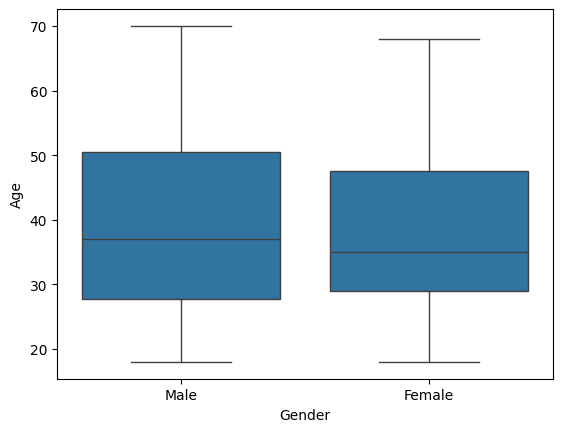

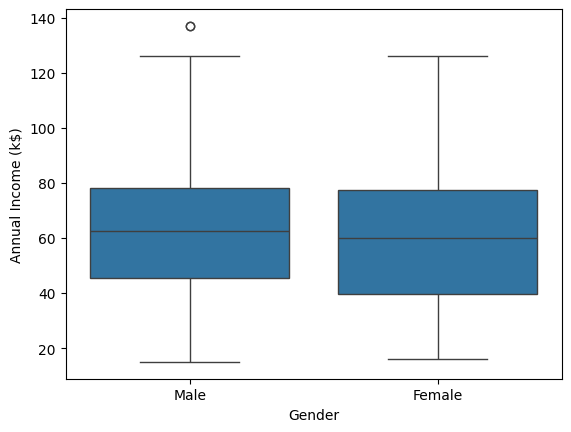

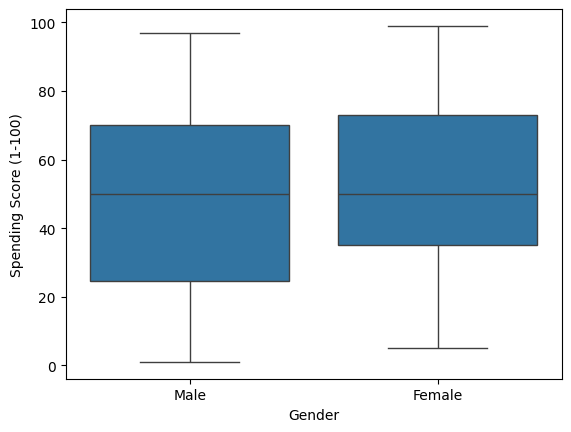

In [8]:
columns = ['Age', 'Annual Income (k$)',
       'Spending Score (1-100)']
for i in columns:
    plt.figure()
    sns.boxplot(data=df, x='Gender', y=df[i])

In [9]:
df['Gender'].value_counts(normalize=True)

,proportion
Gender,
Female,0.56
Male,0.44


Pairplots help visualize the relationships between multiple numerical variables, and coloring by gender adds another layer of analysis by showing how these relationships differ between male and female customers.

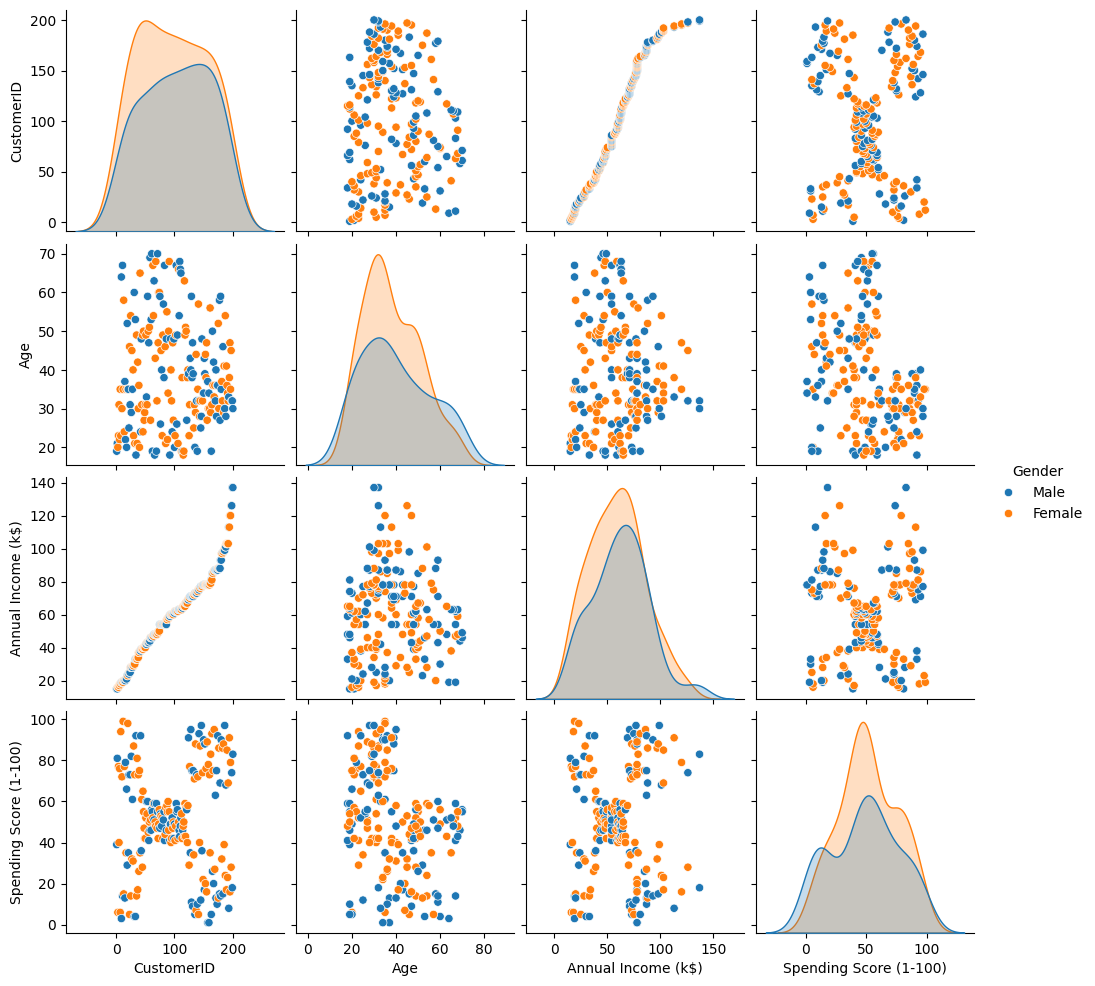

In [10]:
sns.pairplot(df, hue='Gender')

In [11]:
df.groupby(['Gender'])[['Age', 'Annual Income (k$)',
       'Spending Score (1-100)']].mean()

,Age,Annual Income (k$),Spending Score (1-100)
Gender,,,
Female,38.098214,59.250000,51.526786
Male,39.806818,62.227273,48.511364


In [12]:
df.corr(numeric_only=True)

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
CustomerID,1.000000,-0.026763,0.977548,0.013835
Age,-0.026763,1.000000,-0.012398,-0.327227
Annual Income (k$),0.977548,-0.012398,1.000000,0.009903
Spending Score (1-100),0.013835,-0.327227,0.009903,1.000000


The sns.heatmap() function provides a visual representation of these relationships, and the annot=True argument ensures that the actual correlation values are displayed on the heatmap for easy reference. This helps in identifying which features have strong correlations and which don't, aiding in feature selection for customer segmentation.

<Axes: >

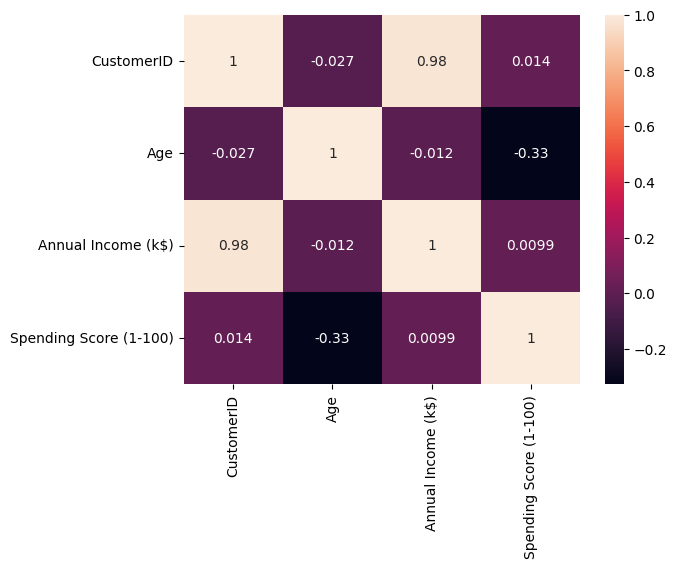

In [13]:
sns.heatmap(df.corr(numeric_only=True), annot=True)

#Clustering Univariate,Bivariate

We apply K-Means Clustering on Annual Income to segment customers into groups. After training the model with 6 clusters, we assign each customer a cluster label and analyze the cluster distribution. We then calculate the inertia (within-cluster variation) to assess clustering quality. Finally, using the Elbow Method, we determine the optimal number of clusters by plotting inertia scores for different cluster counts.

In [28]:
clustering1 = KMeans(n_clusters=6, random_state=42)

In [15]:
clustering1.fit(df[['Annual Income (k$)']])

KMeans(n_clusters=6)

In [16]:
clustering1.labels_


array([5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5,
       3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4,
       4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4,
       4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2], dtype=int32)

In [17]:
df['Income Cluster'] = clustering1.labels_

In [18]:
df.tail()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Income Cluster
195,196,Female,35,120,79,2
196,197,Female,45,126,28,2
197,198,Male,32,126,74,2
198,199,Male,32,137,18,2
199,200,Male,30,137,83,2


In [19]:
df['Income Cluster'].value_counts()

,count
Income Cluster,
0,56
4,50
1,36
5,22
2,20
3,16


In [20]:
clustering1.inertia_

7509.463001443

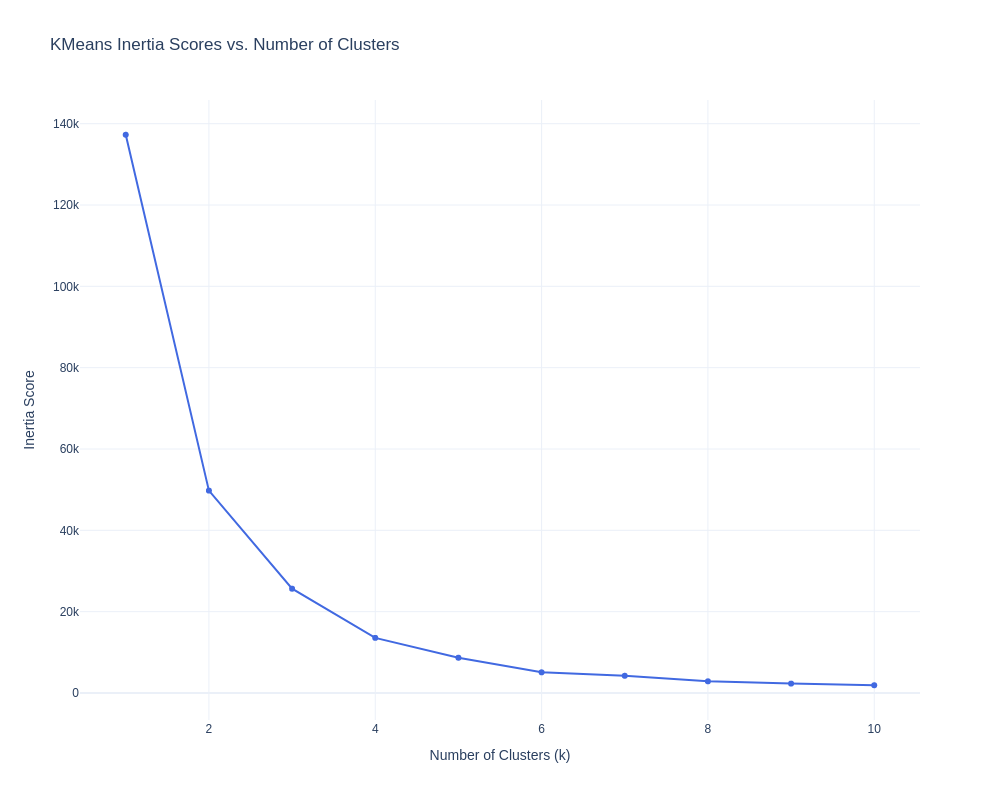

In [29]:
import plotly.graph_objects as go
import plotly.express as px
import plotly.io as pio
from sklearn.cluster import KMeans
import pandas as pd

# Force Plotly to render static PNGs via Kaleido so GitHub displays them
pio.renderers.default = "png"

# Assuming df is already defined and contains 'Annual Income (k$)' column
inertia_scores = []

for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, random_state=42)
    kmeans.fit(df[['Annual Income (k$)']])
    inertia_scores.append(kmeans.inertia_)

# Create the line plot using Plotly
fig = go.Figure()
fig.add_trace(go.Scatter(
    x=list(range(1, 11)),
    y=inertia_scores,
    mode='lines+markers',
    name='Inertia Scores',
    line=dict(color='royalblue', width=2),
    marker=dict(color='royalblue', size=6)
))

# Add title and labels
fig.update_layout(
    title='KMeans Inertia Scores vs. Number of Clusters',
    xaxis_title='Number of Clusters (k)',
    yaxis_title='Inertia Score',
    template='plotly_white',
    width=1000, height=800
)

# Show the plot
fig.show()

In [22]:
 df.columns

Index(['CustomerID', 'Gender', 'Age', 'Annual Income (k$)',
       'Spending Score (1-100)', 'Income Cluster'],
      dtype='object')

In [23]:
df.groupby('Income Cluster')[['Age', 'Annual Income (k$)',
       'Spending Score (1-100)']].mean()

,Age,Annual Income (k$),Spending Score (1-100)
Income Cluster,,,
0,36.410714,78.892857,49.642857
1,44.250000,43.722222,51.305556
2,36.600000,109.700000,52.000000
3,37.312500,30.000000,46.437500
4,41.520000,60.440000,50.060000
5,33.318182,19.272727,51.227273


we apply K-Means Clustering with 5 clusters using both Annual Income and Spending Score to group customers based on these two variables. The cluster labels are stored in a new column, and we analyze the data to see the segmentation. Additionally, we calculate the inertia scores for different numbers of clusters and plot them to determine the optimal cluster count using the Elbow Method.

In [30]:
clustering2 = KMeans(n_clusters=5, random_state=42)
clustering2.fit(df[['Annual Income (k$)', 'Spending Score (1-100)']])
df['Spending and Income Cluster'] = clustering2.labels_
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Income Cluster,Spending and Income Cluster
0,1,Male,19,15,39,5,4
1,2,Male,21,15,81,5,2
2,3,Female,20,16,6,5,4
3,4,Female,23,16,77,5,2
4,5,Female,31,17,40,5,4


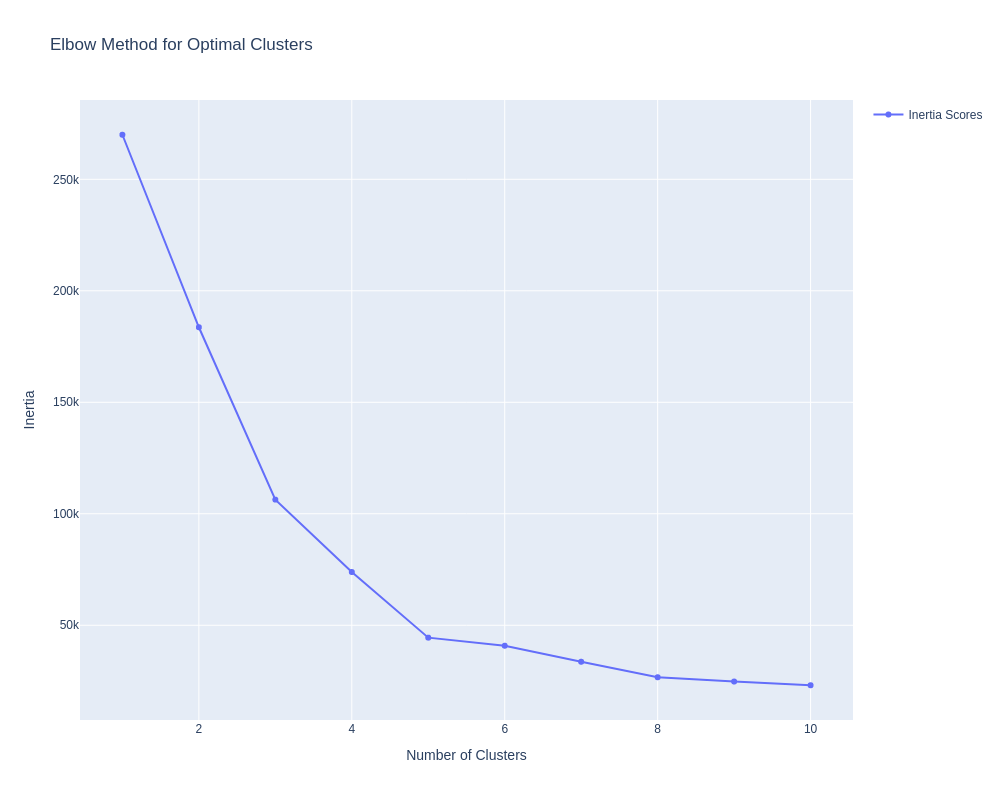

In [31]:
import plotly.graph_objects as go
import plotly.express as px
import plotly.io as pio
from sklearn.cluster import KMeans
import pandas as pd

# Force Plotly to render static PNGs via Kaleido so GitHub displays them
pio.renderers.default = "png"

# Assuming df is your dataframe containing 'Annual Income (k$)' and 'Spending Score (1-100)'

inertia_scores2 = []
for i in range(1, 11):
    kmeans2 = KMeans(n_clusters=i, random_state=42)
    kmeans2.fit(df[['Annual Income (k$)', 'Spending Score (1-100)']])
    inertia_scores2.append(kmeans2.inertia_)

# Create the plot using Plotly
fig = go.Figure()
fig.add_trace(go.Scatter(
    x=list(range(1, 11)),
    y=inertia_scores2,
    mode='lines+markers',
    name='Inertia Scores'
))

# Add titles and labels
fig.update_layout(
    title='Elbow Method for Optimal Clusters',
    xaxis_title='Number of Clusters',
    yaxis_title='Inertia',
    showlegend=True,
    width=1000, height=800

)

# Show the plot
fig.show()

In [26]:
centers = pd.DataFrame(clustering2.cluster_centers_)
centers.columns = ['x', 'y']

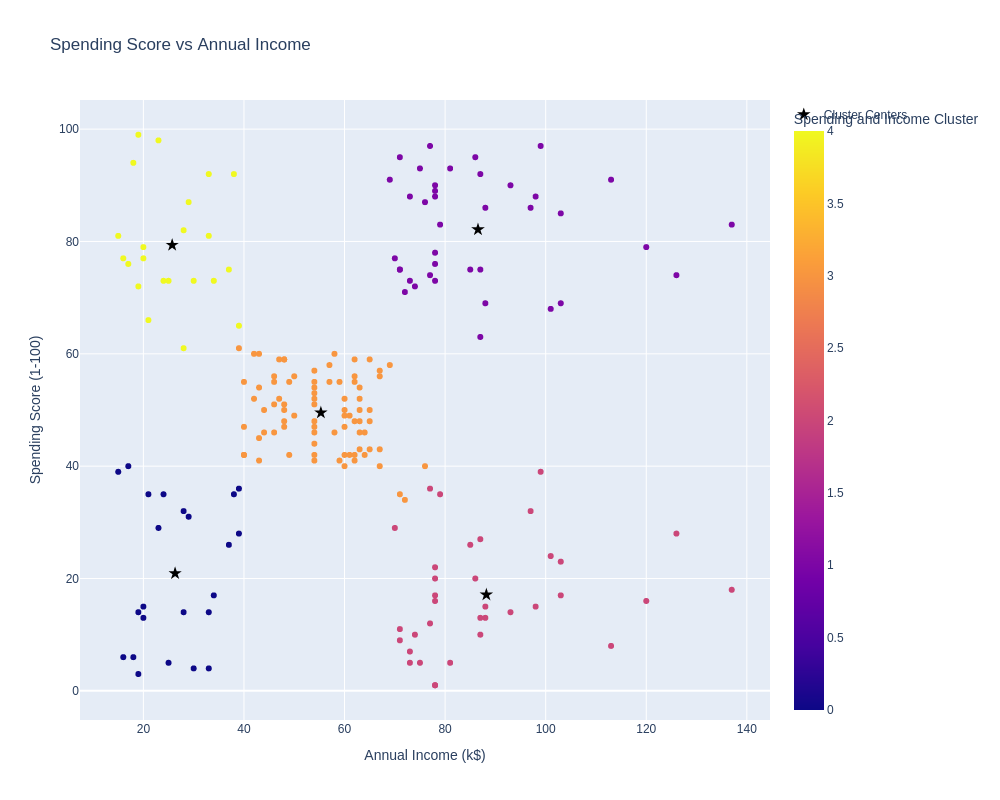

In [27]:
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio

# Force Plotly to render static PNGs via Kaleido so GitHub displays them
pio.renderers.default = "png"

# Create the scatter plot for clusters using Plotly
fig = px.scatter(df,
                 x='Annual Income (k$)',
                 y='Spending Score (1-100)',
                 color='Spending and Income Cluster',
                 color_discrete_sequence=px.colors.qualitative.Set2,
                 title="Spending Score vs Annual Income")

# Add cluster centers with black star markers
fig.add_trace(go.Scatter(x=centers['x'],
                         y=centers['y'],
                         mode='markers',
                         marker=dict(size=10, color='black', symbol='star'),
                         name='Cluster Centers'))

# Update layout
fig.update_layout(width=1000, height=800)

# Show plot
fig.show()

The final customer segmentation visualized above represents the outcome of K-Means clustering applied to mall customers based on their annual income and spending scores. This segmentation highlights five distinct customer clusters, each with unique characteristics in terms of income and spending behavior.

Key takeaways from the segmentation:



*   Low Income, Low Spending (Yellow Cluster): Represents cost-conscious shoppers with low spending potential.
*  Low Income, High Spending (Orange Cluster): Customers with lower income who spend significantly, possibly aspirational or impulsive buyers.
*  Moderate Income, Moderate Spending (Purple Cluster): The typical middle-income, moderate-spending group, representing the average mall customer.
*  High Income, Low Spending (Blue Cluster): High-income individuals who are conservative spenders, indicating value-conscious behavior.
*  High Income, High Spending (Pink Cluster): Affluent customers with high spending potential, prime targets for luxury marketing.



This segmentation helps businesses to:

* Target high-value customers with personalized marketing strategies.
* Design special promotions for budget-conscious groups to increase spending.
* Optimize product offerings and services based on customer profiles